# Partie B – Avis Utilisateurs & Locations



## Imports

In [1]:
!pip install requests beautifulsoup4 fake_useragent pandas -q

import requests
from bs4 import BeautifulSoup
from fake_useragent import UserAgent
import json, time, random, re, os, shutil
import pandas as pd

BASE_URL         = 'https://www.tripadvisor.com'
REVIEWS_PER_PAGE = 15
ua = UserAgent()



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Chargement du Top 500

In [2]:
shutil.copy('data/top_500_restaurants.json', 'data/top_500_restaurants_copy.json')
with open('data/top_500_restaurants.json', 'r', encoding='utf-8') as f:
    data = json.load(f)
filtered = {k: v for k, v in data.items() if re.search(r'-d\d+', v.get('link', ''))}
print(f'{len(filtered)} restaurants chargés')

500 restaurants chargés


## Session + make_request

In [3]:
def create_session():
    session = requests.Session()
    session.cookies.update({
        'TASession': 'V2ID.BD48E47A2CBDBC715939496D7AAB4154*SQ.10*LS.Home*HS.recommended*ES.popularity*DS.5*SAS.popularity*FPS.oldFirst*FA.1*DF.0*TRA.true',
        'TART'     : '%1%enc%3AlvTPBmojRuJ86bDEhmGSBV50mj3CVtwY2eBPZWrGh4Zu0jHhxhwWsxKKOHeS%2FyPaFYc8EBJlDZc%3D',
        '__vt'     : '18Qrtk1oy4qjAe-bABQCT24E-H_BQo6gx1APGQJPtzzihO-HOUbjrz73nKB7zXadjG7Nby5OjGuf7KSUoy2ZetczIrLBEjG9-TwnfzuE4IHgD3qzRavV7-_FtEiywZRa3_9XvYyI2pzA9eC8ABQX5U-HDA',
        '__eoi'    : '942446029da9715f:T=1774907925:RT=1776523619:S=AA-AfjbbaRzvnSiDMcsWNhV7D4GR',
        '_gcl_au'  : '1.1.462798067.1774907923',
    })
    session.headers.update({
        'User-Agent'     : 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36',
        'Accept'         : 'text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8',
        'Accept-Language': 'fr-FR,fr;q=0.9,en-US;q=0.8',
        'Accept-Encoding': 'gzip, deflate, br',
        'Connection'     : 'keep-alive',
        'Referer'        : 'https://www.tripadvisor.com/',
    })
    try:
        resp = session.get('https://www.tripadvisor.com', timeout=15)
        print(f'  → Session créée (status={resp.status_code}, cookies={len(session.cookies)})')
    except Exception as e:
        print(f' Erreur : {e}')
    return session

session = create_session()
request_count = 0

def make_request(url):
    global session, request_count
    request_count += 1
    if request_count % 50 == 0:
        print('  Renouvellement de session...')
        session = create_session()
        time.sleep(random.uniform(5, 10))
    attempt = 0
    while True:
        attempt += 1
        time.sleep(random.uniform(2, 5))
        try:
            session.headers.update({'User-Agent': ua.random, 'Referer': BASE_URL + '/'})
            resp = session.get(url, timeout=15)
            if resp.status_code == 200:
                return resp
            elif resp.status_code in [403, 429]:
                wait = min(60 * attempt, 300) + random.uniform(10, 30)
                print(f'  Bloqué ({resp.status_code}) – pause {wait:.0f}s + nouvelle session...')
                time.sleep(wait)
                session = create_session()
                if attempt >= 3:
                    attempt = 0
            else:
                time.sleep(10)
        except Exception as e:
            print(f'  Erreur : {e} – réessai 10s')
            time.sleep(10)



  → Session créée (status=403, cookies=7)


## URL paginée + comptage avis

In [4]:
def build_reviews_url(base_link, offset):
    if offset == 0:
        return base_link
    new_url = re.sub(r'(Reviews-)([^-])', rf'\1or{offset}-\2', base_link)
    if new_url == base_link:
        new_url = base_link.replace('-Reviews-', f'-Reviews-or{offset}-')
    return new_url

def get_total_reviews(soup):
    for tag in soup.find_all(['span', 'div', 'a', 'button']):
        text = tag.get_text(strip=True)
        m = re.search(r'([\d,\s]+)\s*(avis|review)', text, re.IGNORECASE)
        if m:
            cleaned = re.sub(r'[^\d]', '', m.group(1))
            if not cleaned:
                continue
            total = int(cleaned)
            if 1 <= total <= 100000:
                return total
    return None



## Extraction — location incluse directement


In [5]:
def extract_reviews_from_page(soup):
    reviews = []
    for user_infos in soup.find_all('div', class_='_c'):

        # ── Nom utilisateur ──────────────────────────────────────────────────
        try:
            user_el   = user_infos.find('a', class_='BMQDV _F Gv wSSLS SwZTJ FGwzt ukgoS')
            user_name = user_el.text.strip() if user_el else 'no name'
        except:
            user_name = 'no name'

        # ── Location ─────────────────────────────────────────────────────────
        # HTML : <div class="biGQs _P navcl"><span>Dublin, Ireland</span></div>
        # si pas de location, TripAdvisor met "X contributions" ici
        location = 'no location'
        try:
            loc_el = user_infos.find('div', class_='biGQs _P navcl')
            if loc_el:
                span = loc_el.find('span')
                if span:
                    text = span.text.strip()
                    # Filtrer "X contributions" et autres valeurs parasites
                    if text and not re.search(r'contribution|avis|review|niveau|level|badge', text, re.IGNORECASE):
                        location = text
        except:
            pass


        # ── Texte de l'avis ──────────────────────────────────────────────────
        try:
            review = user_infos.find('span', class_='JguWG').text.strip()
        except:
            review = 'no review'


        # ── Lien profil ──────────────────────────────────────────────────────
        try:
            user_profile_link = BASE_URL + user_el['href'].strip() if user_el and user_el.has_attr('href') else 'no link'
        except:
            user_profile_link = 'no link'

        if user_name != 'no name' or location != 'no location':
            reviews.append({
                'user_name'        : user_name,
                'location'         : location,
                'review'           : review,
                'user_profile_link': user_profile_link,
            })
    return reviews

## Scraping principal avec pagination et checkpoint

In [6]:
CHECKPOINT = 'data/restaurants_visitors_partial.json'

if os.path.exists(CHECKPOINT):
    with open(CHECKPOINT, 'r', encoding='utf-8') as f:
        restaurants_visitors = json.load(f)
else:
    restaurants_visitors = {}
    print(' Démarrage depuis le début\n')

print(f'Scraping des avis – {len(filtered)} restaurants\n')

for i, (name, value) in enumerate(filtered.items(), start=1):

    if name in restaurants_visitors:
        continue

    all_reviews   = []
    offset        = 0
    review_page   = 1
    total_reviews = None

    print(f'[{i:>3}/{len(filtered)}] {name[:55]}')

    while True:
        url  = build_reviews_url(value['link'], offset)
        resp = make_request(url)
        soup = BeautifulSoup(resp.text, 'html.parser')

        if review_page == 1:
            total_reviews = get_total_reviews(soup)

        page_reviews = extract_reviews_from_page(soup)
        all_reviews.extend(page_reviews)

        if not page_reviews:
            break
        if total_reviews and len(all_reviews) >= total_reviews:
            break
        if len(page_reviews) < REVIEWS_PER_PAGE:
            break

        offset      += REVIEWS_PER_PAGE
        review_page += 1
        time.sleep(random.uniform(1, 2))

    # Statistiques locations
    with_loc = sum(1 for r in all_reviews if r.get('location', 'no location') != 'no location')
    print(f'         → {len(all_reviews)} avis ({review_page} pages) | {with_loc} locations | total déclaré: {total_reviews}')

    restaurants_visitors[name] = {
        'link'   : value['link'],
        'rate'   : value.get('rate'),
        'reviews': all_reviews,
    }

    if i % 2 == 0:
        with open(CHECKPOINT, 'w', encoding='utf-8') as f:
            json.dump(restaurants_visitors, f, ensure_ascii=False, indent=4)
        print(f'  Checkpoint ({len(restaurants_visitors)}/{len(filtered)} restaurants)')

    time.sleep(random.uniform(2, 4))

# Sauvegarde finale
with open('data/restaurants_visitors.json', 'w', encoding='utf-8') as f:
    json.dump(restaurants_visitors, f, ensure_ascii=False, indent=4)

print('data/restaurants_visitors.json sauvegardé')

Scraping des avis – 500 restaurants

data/restaurants_visitors.json sauvegardé


##  Classement Nationalités ( depuis les avis)



In [7]:
!pip install pycountry -q

import json
import re
import pycountry
import matplotlib.pyplot as plt
from collections import Counter

with open('data/restaurants_visitors.json', 'r', encoding='utf-8') as f:
    data = json.load(f)



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
# ── Noms alternatifs non couverts par pycountry ─────────────
ALIASES = {
    'Uk': 'United Kingdom', 'England': 'United Kingdom',
    'Scotland': 'United Kingdom', 'Wales': 'United Kingdom',
    'Northern Ireland': 'United Kingdom',
    'Usa': 'United States', 'Dc': 'United States',
    'España': 'Spain', 'Deutschland': 'Germany',
    'Suisse': 'Switzerland', 'Schweiz': 'Switzerland',
    'Belgique': 'Belgium', 'België': 'Belgium',
    'Italia': 'Italy', 'Türkiye': 'Turkey',
    'Maroc': 'Morocco', 'Niederlande': 'Netherlands',
    'Österreich': 'Austria', 'Polska': 'Poland',
    'Norge': 'Norway',
}

GARBAGE = {
    'World', 'Earth', 'Europe', 'Asia', 'Africa',
    'South America', 'North America', 'Caribbean',
    'Staymonth=12', 'The North', 'New England',
}

# ── États US ─────────────────────────────────────────────────
US_STATES = {s.name for s in pycountry.subdivisions.get(country_code='US')}
US_STATES.update({
    'Ca', 'Ny', 'Fl', 'Tx', 'Il', 'Ma', 'Ga', 'Wa', 'Va',
    'Pa', 'Co', 'Nj', 'Mn', 'Md', 'Nc', 'Az', 'Ct', 'Oh',
    'Or', 'Wi', 'Mi', 'Nv', 'In', 'Mo', 'Sc', 'Me', 'Ky',
    'Ut', 'Vt', 'Nm', 'Hi', 'De', 'Ri', 'Ne', 'Id', 'Ok',
    'Ar', 'Nd', 'Ak', 'Ks', 'Mt', 'Wy', 'Wv', 'La', 'Ms',
    'Ia', 'Al', 'Tn', 'Nh', 'Sd', 'Dc', 'Pr',
    'District Of Columbia', 'Puerto Rico',
})

# ── Villes → pays ────────────────────────────────────────────
CITY_TO_COUNTRY = {
    'London': 'United Kingdom', 'Manchester': 'United Kingdom',
    'Birmingham': 'United Kingdom', 'Glasgow': 'United Kingdom',
    'Edinburgh': 'United Kingdom', 'Bristol': 'United Kingdom',
    'Cardiff': 'United Kingdom', 'Belfast': 'United Kingdom',
    'Dublin': 'Ireland', 'Cork': 'Ireland',
    'Paris': 'France', 'Lyon': 'France', 'Bordeaux': 'France',
    'Nantes': 'France', 'Toulouse': 'France', 'Rennes': 'France',
    'Madrid': 'Spain', 'Barcelona': 'Spain',
    'Rome': 'Italy', 'Roma': 'Italy', 'Milano': 'Italy',
    'Amsterdam': 'Netherlands', 'Oslo': 'Norway',
    'Copenhagen': 'Denmark', 'Stockholm': 'Sweden',
    'Budapest': 'Hungary', 'Warsaw': 'Poland',
    'Istanbul': 'Turkey', 'Athens': 'Greece',
    'Toronto': 'Canada', 'Montreal': 'Canada', 'Vancouver': 'Canada',
    'Melbourne': 'Australia', 'Sydney': 'Australia', 'Brisbane': 'Australia',
    'Auckland': 'New Zealand', 'Tokyo': 'Japan',
    'Beijing': 'China', 'Shanghai': 'China', 'Seoul': 'South Korea',
    'Bangkok': 'Thailand', 'Berlin': 'Germany', 'Hamburg': 'Germany',
    'Frankfurt': 'Germany', 'Vienna': 'Austria',
    'Zurich': 'Switzerland', 'Geneva': 'Switzerland',
    'Marrakech': 'Morocco', 'Marrakesh': 'Morocco',
    'Casablanca': 'Morocco', 'Rabat': 'Morocco',
    'Dubai': 'United Arab Emirates', 'Dubia': 'United Arab Emirates',
    'Lisboa': 'Portugal', 'Lisbona': 'Portugal', 'Porto': 'Portugal',
    'New York City': 'United States', 'Los Angeles': 'United States',
    'Chicago': 'United States', 'Miami': 'United States',
    'San Francisco': 'United States', 'Seattle': 'United States',
    'Atlanta': 'United States',
}


def normalize_country(raw):
    raw = raw.strip().title()
    if raw in GARBAGE:
        return None
    if raw in ALIASES:
        return ALIASES[raw]
    try:
        match = pycountry.countries.search_fuzzy(raw)
        if match:
            return match[0].name
    except LookupError:
        pass
    return None


def resolve(raw):
    raw = raw.strip().title()
    if raw in CITY_TO_COUNTRY:
        return CITY_TO_COUNTRY[raw]
    if raw in US_STATES:
        return 'United States'
    return normalize_country(raw)


In [11]:
country_profiles = {}
seen_profiles    = set()
total_reviews    = 0
no_location      = 0

for info in data.values():
    for review in info.get('reviews', []):
        total_reviews += 1

        profile = review.get('user_profile_link', '') or review.get('user_name', '')
        if profile and profile not in ('no link', ''):
            seen_profiles.add(profile)

        loc = review.get('location', '')

        if not loc or loc in ('no location', ''):
            no_location += 1
            continue

        if re.search(r'contribution|avis|review|niveau|level|badge|\d{4,}|@',
                     loc, re.IGNORECASE):
            no_location += 1
            continue

        parts   = [p.strip() for p in loc.split(',')]
        country = resolve(parts[-1])

        if country is None:
            no_location += 1
            continue

        if profile and profile not in ('no link', ''):
            country_profiles.setdefault(country, set()).add(profile)

country_counter = Counter({k: len(v) for k, v in country_profiles.items()})

no_location_profiles   = seen_profiles - {p for v in country_profiles.values() for p in v}
with_location_profiles = len(seen_profiles) - len(no_location_profiles)
total_profiles         = len(seen_profiles)

print(f"Total avis          : {total_reviews:,}")
print(f"Profils uniques     : {total_profiles:,}")
print(f"Avec localisation   : {with_location_profiles:,}  ({with_location_profiles/total_profiles*100:.1f}%)")
print(f"Sans localisation   : {len(no_location_profiles):,}  ({len(no_location_profiles)/total_profiles*100:.1f}%)")
print(f"Pays détectés       : {len(country_counter)}\n")



Total avis          : 58,091
Profils uniques     : 54,281
Avec localisation   : 20,472  (37.7%)
Sans localisation   : 33,809  (62.3%)
Pays détectés       : 149



In [12]:
print(f"{'Rang':<6} {'Pays':<35} {'Visiteurs uniques':>17}")
print("-" * 60)
for rank, (country, count) in enumerate(country_counter.most_common(), start=1):
    print(f"{rank:<6} {country:<35} {count:>17,}")
print("-" * 60)
print(f"{'TOTAL':<41} {sum(country_counter.values()):>17,}")


Rang   Pays                                Visiteurs uniques
------------------------------------------------------------
1      United Kingdom                                  5,330
2      France                                          3,355
3      Italy                                           1,629
4      United States                                   1,593
5      Spain                                           1,330
6      Morocco                                         1,137
7      Netherlands                                       660
8      Germany                                           582
9      Belgium                                           537
10     Switzerland                                       492
11     Portugal                                          469
12     Canada                                            379
13     Ireland                                           300
14     Australia                                         292
15     Denmark          

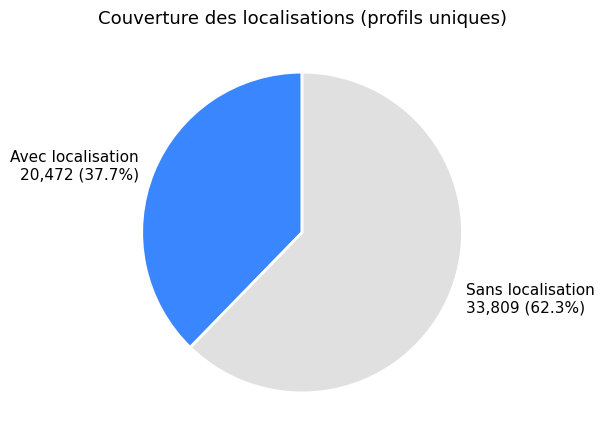

In [13]:
# ── Pie — couverture localisations ───────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    [with_location_profiles, len(no_location_profiles)],
    labels=[
        f'Avec localisation\n{with_location_profiles:,} ({with_location_profiles/total_profiles*100:.1f}%)',
        f'Sans localisation\n{len(no_location_profiles):,} ({len(no_location_profiles)/total_profiles*100:.1f}%)',
    ],
    colors=['#3A86FF', '#E0E0E0'],
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 11},
)
ax.set_title('Couverture des localisations (profils uniques)', fontsize=13)
plt.tight_layout()
plt.savefig('data/couverture_localisation.png', dpi=150, bbox_inches='tight')
plt.show()



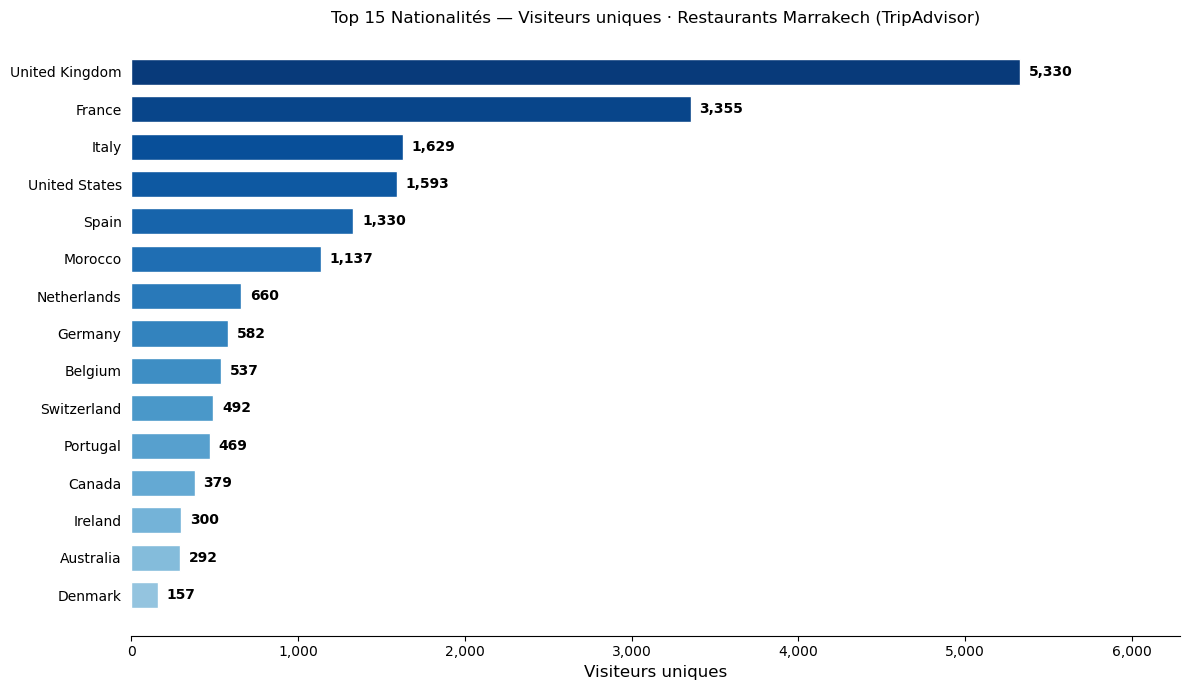

In [14]:
# ── Barh — Top 15 nationalités ───────────────────────────────
top15  = country_counter.most_common(15)
pays   = [x[0] for x in reversed(top15)]
counts = [x[1] for x in reversed(top15)]
colors = plt.cm.Blues([0.4 + 0.6 * (i / len(pays)) for i in range(len(pays))])

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(pays, counts, color=colors, edgecolor='white', height=0.7)
for bar, val in zip(bars, counts):
    ax.text(bar.get_width() + max(counts) * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f'{val:,}', va='center', ha='left', fontsize=10, fontweight='bold')

ax.set_xlabel('Visiteurs uniques', fontsize=12)
ax.set_title('Top 15 Nationalités — Visiteurs uniques · Restaurants Marrakech (TripAdvisor)')
ax.set_xlim(0, max(counts) * 1.18)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(left=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.savefig('data/top15_nationalites.png', dpi=150, bbox_inches='tight')
plt.show()
